# EDA: Wikipedia match data (All-Ireland SFC season pages, 2021-2024)

A first look at what the collection step gave us, before the pilot. The questions are simple:
how many matches do we really have, how are they spread, why did some get dropped, how messy is
the scorer notation the model will have to read, and is the pilot a reasonable slice of the rest.

Inputs come from `data/processed/` (written by `parse_matches.py` and `export_pilot_inputs.py`).
Figures are saved to `notebooks/figures/`.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# find the repo root no matter where the notebook is launched from
ROOT = Path.cwd().resolve()
while not (ROOT / 'scripts' / 'parse_matches.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

PROC = ROOT / 'data' / 'processed'
FIGS = ROOT / 'notebooks' / 'figures'
FIGS.mkdir(parents=True, exist_ok=True)

# reuse the parser helpers so the counts below read the match boxes exactly like the sum test does
sys.path.insert(0, str(ROOT / 'scripts'))
import parse_matches as pm

# one blue for "the data", orange only for the pilot, grey for everything else
BLUE, ORANGE, GREY = '#2f5d8a', '#e08a1e', '#9aa5b1'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def save(fig, name):
    # same two lines after every plot, so keep them in one place
    fig.tight_layout()
    fig.savefig(FIGS / name, dpi=150)
    plt.show()

## Load the data

In [2]:
inc = pd.read_csv(PROC / 'matches_included.csv')
exc = pd.read_csv(PROC / 'matches_exclusions.csv')
pilot = json.loads((PROC / 'pilot_inputs.json').read_text(encoding='utf-8'))
pilot_keys = {(g['year'], g['line']) for g in pilot}

# score_listed looks like "2-14 v 1-16". Pull out goals and points for each side
# and convert to total points (1 goal = 3 points), since that's what decides a match.
def split_score(s):
    (g1, p1), (g2, p2) = re.findall(r'(\d+)-(\d+)', s)
    return int(g1), int(p1), int(g2), int(p2)

inc[['g1', 'p1', 'g2', 'p2']] = inc['score_listed'].apply(lambda s: pd.Series(split_score(s)))
inc['pts1'] = inc['g1'] * 3 + inc['p1']
inc['pts2'] = inc['g2'] * 3 + inc['p2']
inc['total'] = inc['pts1'] + inc['pts2']
inc['margin'] = (inc['pts1'] - inc['pts2']).abs()

# (year, line) identifies a match box, same key the pilot sampling used
inc['pilot'] = [(y, l) in pilot_keys for y, l in zip(inc['year'], inc['line'])]

print(f'{len(inc)} included, {len(exc)} excluded, {len(inc) + len(exc)} match boxes in total')
print(f'pilot matches found in the included set: {inc.pilot.sum()} of {len(pilot)}')

122 included, 32 excluded, 154 match boxes in total
pilot matches found in the included set: 9 of 10


## How many matches per season?

,included,excluded,total
year,,,
2021,4,3,7
2022,15,4,19
2023,49,15,64
2024,54,10,64


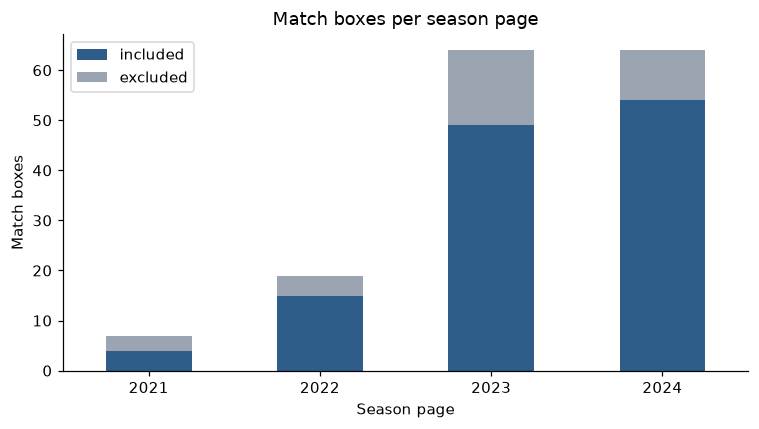

In [3]:
# groupby().size() skips years with nothing excluded, so fill the gaps with 0
by_year = pd.DataFrame({'included': inc.groupby('year').size(),
                        'excluded': exc.groupby('year').size()}).fillna(0).astype(int)
by_year['total'] = by_year.sum(axis=1)
display(by_year)

fig, ax = plt.subplots(figsize=(7, 4))
by_year[['included', 'excluded']].plot.bar(stacked=True, ax=ax, color=[BLUE, GREY], rot=0)
ax.set_xlabel('Season page')
ax.set_ylabel('Match boxes')
ax.set_title('Match boxes per season page')
save(fig, 'fig1_matches_per_year.png')

2021 and 2022 are thin: 7 and 19 boxes against 64 in each of 2023 and 2024. I haven't opened those pages
yet to see why, so for now this is a limit to state, not something explained.

## Why were matches dropped?

,matches
reason,
extra_time,13
no_scorers,10
sum_mismatch,7
parse_error,2


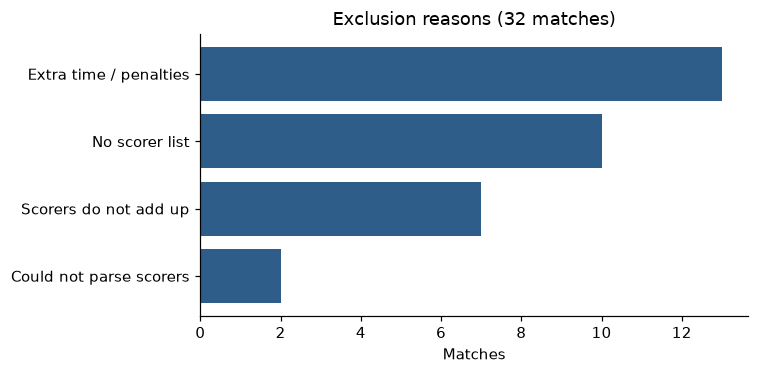

In [4]:
reasons = exc['reason'].value_counts()
display(reasons.to_frame('matches'))

# readable names for the plot; anything new falls back to the raw reason code
labels = {'no_scorers': 'No scorer list', 'sum_mismatch': 'Scorers do not add up',
          'extra_time': 'Extra time / penalties', 'parse_error': 'Could not parse scorers',
          'no_score': 'No final score'}

# barh draws the first item at the bottom, so reverse to get the biggest bar on top
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh([labels.get(r, r) for r in reasons.index][::-1], reasons.values[::-1], color=BLUE)
ax.set_xlabel('Matches')
ax.set_title(f'Exclusion reasons ({len(exc)} matches)')
save(fig, 'fig2_exclusion_reasons.png')

### The sum test failures, one by one

In [5]:
# For the matches that failed the sum test: how far off were the scorers?
# The parser stored what the scorers add up to in `detail`, so compare that with the listed score.
def to_pts(text):
    return [int(g) * 3 + int(p) for g, p in re.findall(r'(\d+)-(\d+)', text)]

rows = []
for _, r in exc[exc.reason == 'sum_mismatch'].iterrows():
    listed, summed = to_pts(r['score_listed']), to_pts(r['detail'])
    rows.append({'year': r['year'], 'line': r['line'], 'match': f"{r['team1']} v {r['team2']}",
                 'listed': r['score_listed'], 'scorers add up to': r['detail'].replace('scorers sum to ', ''),
                 'gap team1 (pts)': summed[0] - listed[0], 'gap team2 (pts)': summed[1] - listed[1]})

mismatch = pd.DataFrame(rows)
display(mismatch)
mismatch.to_csv(FIGS / 'eda_sum_mismatch.csv', index=False)

# gap > 0 means the scorers add up to more than the score, gap < 0 means the list is short
gaps = pd.concat([mismatch['gap team1 (pts)'], mismatch['gap team2 (pts)']])
print('non-zero gaps (points):', sorted(gaps[gaps != 0].tolist()))

,year,line,match,listed,scorers add up to,gap team1 (pts),gap team2 (pts)
0,2021,147,Monaghan v Tyrone,0-15 v 0-16,0-14 v 0-16,-1,0
1,2023,1521,Derry v Clare,1-19 v 1-13,1-16 v 1-13,-3,0
2,2024,292,Leitrim v Sligo,0-6 v 0-15,0-6 v 0-14,0,-1
3,2024,343,Roscommon v Mayo,0-13 v 1-15,0-12 v 1-15,-1,0
4,2024,382,Longford v Meath,3-12 v 3-19,3-11 v 3-19,-1,0
5,2024,414,Wexford v Carlow,4-19 v 0-8,4-18 v 0-8,-1,0
6,2024,734,Down v Armagh,2-6 v 0-13,1-6 v 1-13,-3,3


non-zero gaps (points): [-3, -3, -1, -1, -1, -1, -1, 3]


Five of the seven are exactly one point short, which looks like a scorer missing from the list rather than a
different score. I only checked one of them by hand so far, so until the other six are checked they stay excluded.

## Which rounds do we have?

,matches
round,
quarter-final,28
round 1,20
round 2,20
round 3,15
semi-final,13
final,7
preliminary quarter-final,7
preliminary round,6
leinster final,2


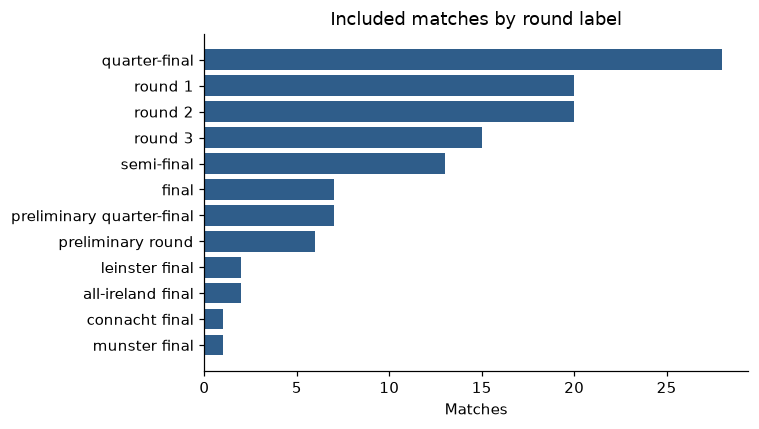

In [6]:
# "Preliminary Round" and "Preliminary round" are the same thing, so lowercase before counting
rounds = inc['round'].str.strip().str.lower().value_counts()
display(rounds.to_frame('matches'))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(rounds.index[::-1], rounds.values[::-1], color=BLUE)
ax.set_xlabel('Matches')
ax.set_title('Included matches by round label')
save(fig, 'fig3_rounds.png')

The round label does not say which competition a match belongs to (a "Semi-final" can be provincial or
All-Ireland), and the group stage has no group name. That is why the prompt only says "Senior Football Championship".

## How close are the matches?

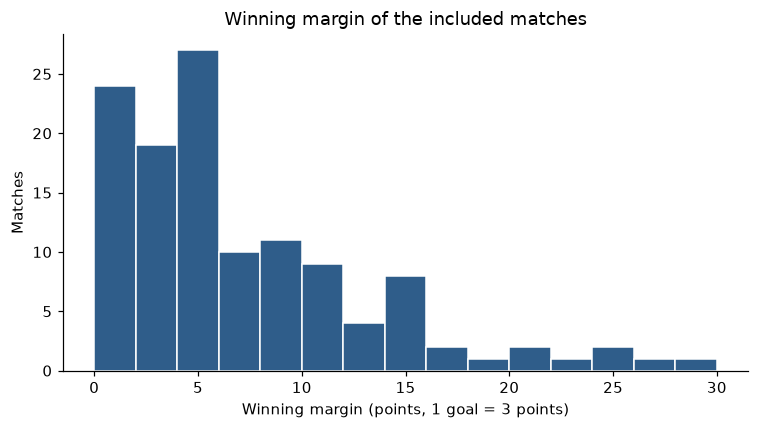

draws: 7
median margin: 5.0 | one-point games: 17


In [7]:
# bins of 2 points so a 1-point game and a draw don't get lost in a wide bar
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(inc['margin'], bins=range(0, int(inc['margin'].max()) + 3, 2), color=BLUE, edgecolor='white')
ax.set_xlabel('Winning margin (points, 1 goal = 3 points)')
ax.set_ylabel('Matches')
ax.set_title('Winning margin of the included matches')
save(fig, 'fig4_margin.png')

print('draws:', (inc['margin'] == 0).sum())
print('median margin:', inc['margin'].median(), '| one-point games:', (inc['margin'] == 1).sum())

## Goals and points

,team performances
0,102
1,78
2,39
3,15
4,4
5,6


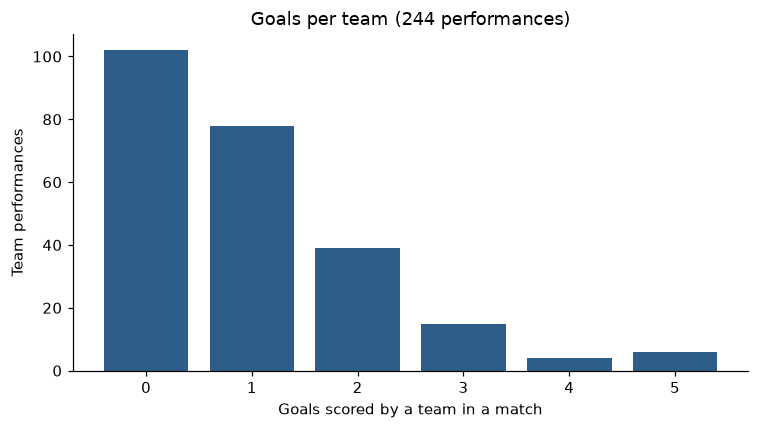

performances with 0 goals: 102 of 244
matches where the team with more goals loses: 11


In [8]:
# Goals are the awkward part for a model: one goal is worth three points, so the winner
# is not always the team with the bigger second number (e.g. 1-14 beats 0-16).
goals = pd.concat([inc['g1'], inc['g2']])
by_goals = goals.value_counts().sort_index()
display(by_goals.to_frame('team performances'))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(by_goals.index.astype(str), by_goals.values, color=BLUE)
ax.set_xlabel('Goals scored by a team in a match')
ax.set_ylabel('Team performances')
ax.set_title(f'Goals per team ({len(goals)} performances)')
save(fig, 'fig6_goals_per_team.png')

# how often does the team with more goals NOT win? those are the cases that need the 3-point rule
flips = ((inc['g1'] > inc['g2']) & (inc['pts1'] < inc['pts2'])) | ((inc['g2'] > inc['g1']) & (inc['pts2'] < inc['pts1']))
print('performances with 0 goals:', (goals == 0).sum(), 'of', len(goals))
print('matches where the team with more goals loses:', flips.sum())

## How messy is the scorer notation?

,% of scorer lists
"free (2f, 2fs, 0-3f)",96
'45 (1 '45),24
penalty (1-0 pen),5
mark,5
"""each"" / ""all"" (0-2 each)",9
any bracket,95


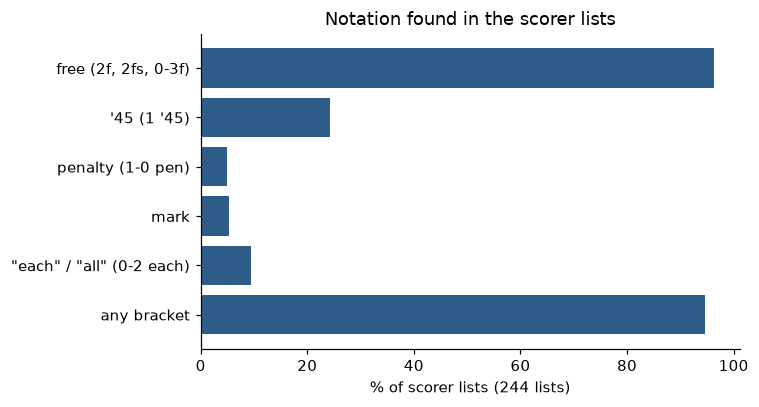

In [9]:
# The model gets the scorer lists as written on Wikipedia, so look at what is actually in them.
# One text per team per match, included matches only.
inc_keys = set(zip(inc['year'], inc['line']))
texts = []
for y in pm.YEARS:
    raw = (pm.RAW / f'{y}.wikitext').read_text(encoding='utf-8')
    for blk in pm.blocks(raw):
        line = raw[:raw.find(blk)].count('\n') + 1
        if (y, line) not in inc_keys:
            continue
        f = pm.fields(blk)
        for side in '12':
            texts.append(' '.join(pm.clean(f.get(k + side, '')) for k in ('goals', 'points')))

# a list can carry several of these at once, so count how many lists contain each one
patterns = {
    'free (2f, 2fs, 0-3f)': r'\d\s*fs?\b|\bfrees?\b',
    "'45 (1 '45)": r"'45|\b45\b",
    'penalty (1-0 pen)': r'\bpen',
    'mark': r'\bmarks?\b',
    '"each" / "all" (0-2 each)': r'\beach\b|\ball\b',
    'any bracket': r'\(',
}
share = pd.Series({name: sum(bool(re.search(p, t, re.I)) for t in texts) / len(texts) for name, p in patterns.items()})
display((share * 100).round(0).astype(int).to_frame('% of scorer lists'))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(share.index[::-1], share.values[::-1] * 100, color=BLUE)
ax.set_xlabel(f'% of scorer lists ({len(texts)} lists)')
ax.set_title('Notation found in the scorer lists')
save(fig, 'fig7_scorer_notation.png')

Most lists carry at least one extra note next to the numbers. The model has to read those notes without
double counting (a free is already inside the player's total), which is where I'd expect the pilot to slip.

## Is the pilot sample a fair slice?

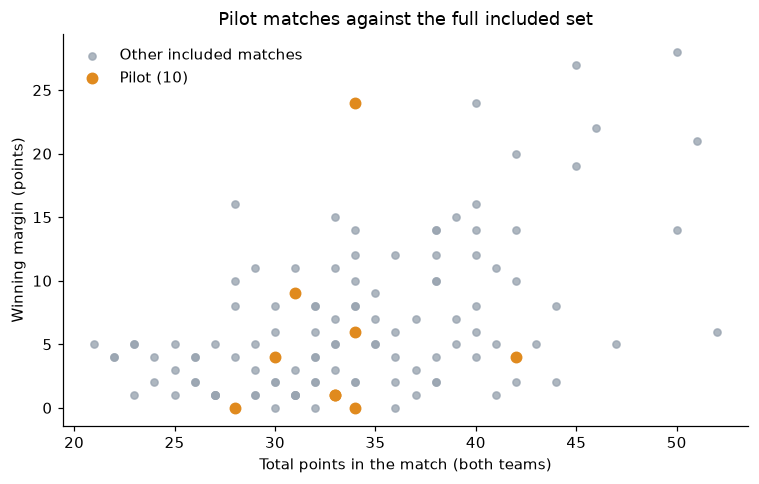

      total            margin           
        min median max    min median max
pilot                                   
False    21   33.0  52      0    5.0  28
True     28   33.0  42      0    4.0  24


In [10]:
# pilot in orange on top of everything else in grey
fig, ax = plt.subplots(figsize=(7, 4.5))
rest = inc[~inc.pilot]
ax.scatter(rest['total'], rest['margin'], s=22, color=GREY, label='Other included matches', alpha=0.8)
ax.scatter(inc[inc.pilot]['total'], inc[inc.pilot]['margin'], s=46, color=ORANGE, label='Pilot (10)')
ax.set_xlabel('Total points in the match (both teams)')
ax.set_ylabel('Winning margin (points)')
ax.set_title('Pilot matches against the full included set')
ax.legend(frameon=False)
save(fig, 'fig5_pilot_vs_rest.png')

print(inc.groupby('pilot')[['total', 'margin']].agg(['min', 'median', 'max']))

With only 10 matches the pilot can't be "representative" in any strong sense. The plot is a sanity check that it
isn't stuck in one corner. Worth noticing: the pilot has no match with a very high total, so high-scoring games are
not covered.

## What can we verify? (coverage)

In [11]:
# half-time score: look for the field in every match box, not only the included ones
HT_KEYS = {'halftime', 'half-time', 'half time', 'ht'}
ht_rows = []
for y in pm.YEARS:
    raw = (pm.RAW / f'{y}.wikitext').read_text(encoding='utf-8')
    for blk in pm.blocks(raw):
        if HT_KEYS & set(pm.fields(blk)):
            ht_rows.append((y, raw[:raw.find(blk)].count('\n') + 1))

ht_in_included = sum((y, l) in inc_keys for y, l in ht_rows)
total = len(inc) + len(exc)

coverage = pd.DataFrame([
    ('Match boxes found', total),
    ('Included (scorers add up to the score)', len(inc)),
    ('Excluded: no scorer list', (exc.reason == 'no_scorers').sum()),
    ('Excluded: extra time / penalties', (exc.reason == 'extra_time').sum()),
    ('Excluded: sum test or parsing failed', exc.reason.isin(['sum_mismatch', 'parse_error', 'no_score']).sum()),
    ('Boxes with a half-time score', len(ht_rows)),
    ('...of which in the included set', ht_in_included),
], columns=['item', 'matches'])
display(coverage)
coverage.to_csv(FIGS / 'eda_coverage.csv', index=False)

,item,matches
0,Match boxes found,154
1,Included (scorers add up to the score),122
2,Excluded: no scorer list,10
3,Excluded: extra time / penalties,13
4,Excluded: sum test or parsing failed,9
5,Boxes with a half-time score,5
6,...of which in the included set,3


Half-time scores exist in only a handful of boxes, so claims about how a match unfolded (who led at the
break, comebacks, scoring runs) are out of reach with this source. What we can check is the final score, the winner, the
scorers with their totals, and the margin. That is the same list as in the Gate 2 decision in the roadmap.

## Does Wikipedia agree with an independent source? (20-match check)

,disagree,n/a,ok
Final score,0,0,20
Date,0,0,20
Winner,0,0,20
Round label,1,3,16
Top scorer (pilot only),0,10,10


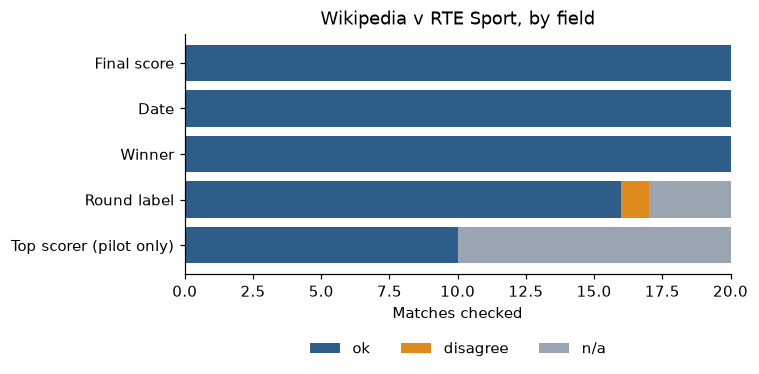

In [12]:
# Results of the hand check against RTE Sport, filled in by me in validation_games.xlsx.
# Needs openpyxl to read the spreadsheet; if it's missing, say so instead of crashing the notebook.
try:
    val = pd.read_excel(PROC / 'validation_games.xlsx', sheet_name='Validation', keep_default_na=False)  # keep_default_na: otherwise pandas turns the text "n/a" into a missing value
except ImportError:
    val = None
    print('openpyxl is not installed (pip install openpyxl), skipping this cell')

if val is not None:
    # the sheet has a summary row under the 20 matches; keep only rows with a numeric match number
    val = val[pd.to_numeric(val['#'], errors='coerce').notna()]

    fields = {'Final score': 'Result (score)', 'Date': 'Date ok?', 'Winner': 'Winner ok?',
              'Round label': 'Round ok?', 'Top scorer (pilot only)': 'Top scorer + total ok? (pilot only)'}
    counts = pd.DataFrame({name: val[col].replace('', 'blank').value_counts() for name, col in fields.items()}).T.fillna(0).astype(int)
    display(counts)

    fig, ax = plt.subplots(figsize=(7, 3.8))
    colours = {'ok': BLUE, 'disagree': ORANGE, 'n/a': GREY, 'blank': '#d9dee3'}
    left = pd.Series(0, index=counts.index)
    for status in [c for c in colours if c in counts.columns]:
        ax.barh(counts.index[::-1], counts[status][::-1], left=left[::-1], color=colours[status], label=status)
        left += counts[status]
    ax.set_xlabel('Matches checked')
    ax.set_title('Wikipedia v RTE Sport, by field')
    ax.legend(frameon=False, ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.4))
    save(fig, 'fig8_validation.png')

Score, date and winner agree in every
match. The only real disagreement is a round label (Laois v Wexford); in the group stage the source adds the group
name, which isn't a contradiction, so those are counted as n/a. Only one source (RTE) was used.